<a href="https://colab.research.google.com/github/ritaveab/Deep-Learning_hse/blob/main/clustering_hw_Baeva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнее задание: кластеризация (K-Means, DBSCAN, OPTICS)

**Данные:** Wine Quality (`wineqr.csv`), 11 числовых химических признаков вина.
Столбец `quality` в кластеризации **не используется**: это обучение без учителя.

**План:**
1. K-Means: метод локтя, силуэт, выбор K, PCA-визуализация.
2. DBSCAN: k-distance graph, перебор параметров, финальная модель, ответы на вопросы.
3. OPTICS: обучение, метрики, reachability plot, ответы на вопросы.

## 0. Подготовка: импорты и загрузка данных

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, OPTICS
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42   # фиксируем для воспроизводимости
np.random.seed(RANDOM_STATE)

Загружаем файл. В Colab нужно загрузить `wineqr.csv` вручную (значок папки слева → «Загрузить»)
либо выполнить ячейку ниже, которая откроет окно выбора файла.

In [3]:
import os
if not os.path.exists('wineqr.csv'):
    from google.colab import files
    files.upload()          # выберите wineqr.csv

df = pd.read_csv('wineqr.csv')
print(df.shape)
df.head()

(1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


Посмотрим на типы данных и пропуски: кластеризация плохо переносит `NaN`.

In [4]:
df.info()
print('Пропусков всего:', df.isna().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB
Пропусков всего: 0


## Часть 1. K-Means

### 1.1 Удаляем `quality` и масштабируем

Если в файле есть служебный столбец `Id` (в некоторых версиях датасета он есть), его тоже убираем:
это просто номер строки, а не химический признак.

**Зачем масштабировать:** K-Means и DBSCAN считают евклидово расстояние. Признаки в разных единицах
(например, `total sulfur dioxide` порядка десятков, а `chlorides` порядка сотых) без масштабирования дадут
вклад пропорционально своему размаху, и «главными» окажутся признаки с большими числами. `StandardScaler` приводит
каждый признак к среднему 0 и стандартному отклонению 1.

In [5]:
drop_cols = [c for c in ['quality', 'Id', 'id'] if c in df.columns]
X_raw = df.drop(columns=drop_cols)
print('Признаки:', list(X_raw.columns))
print('Число признаков:', X_raw.shape[1])

scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

# быстрая проверка: среднее ≈ 0, std ≈ 1
print('mean:', X.mean(axis=0).round(2))
print('std: ', X.std(axis=0).round(2))

Признаки: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Число признаков: 11
mean: [-0.  0.  0.  0.  0. -0.  0.  0. -0.  0. -0.]
std:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 1.2 Цикл по K от 2 до 10

Для каждого K считаем:
- **WCSS** (`inertia_`): сумма квадратов расстояний от точек до центров своих кластеров. Чем меньше, тем компактнее
  кластеры, но она всегда убывает с ростом K, поэтому нужен «локоть».
- **Коэффициент силуэта**: от −1 до 1. Показывает, насколько точка ближе к своему кластеру, чем к соседнему.
  Чем ближе к 1, тем лучше разделение.

In [6]:
K_range = range(2, 11)
wcss = []
sil_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X)
    wcss.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels))
    print(f'K={k}: WCSS={km.inertia_:.0f}, silhouette={sil_scores[-1]:.3f}')

K=2: WCSS=10238, silhouette=0.220
K=3: WCSS=9060, silhouette=0.183
K=4: WCSS=8087, silhouette=0.201
K=5: WCSS=7256, silhouette=0.188
K=6: WCSS=6679, silhouette=0.190
K=7: WCSS=6136, silhouette=0.195
K=8: WCSS=5891, silhouette=0.150
K=9: WCSS=5656, silhouette=0.154
K=10: WCSS=5440, silhouette=0.156


### 1.3 Графики (каждый в своей ячейке)

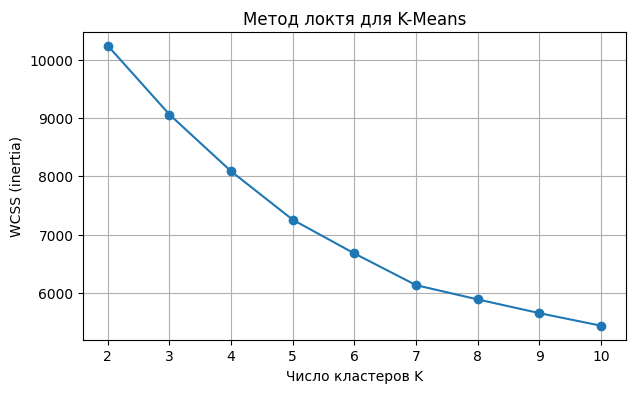

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(list(K_range), wcss, marker='o')
plt.xlabel('Число кластеров K')
plt.ylabel('WCSS (inertia)')
plt.title('Метод локтя для K-Means')
plt.grid(True)
plt.show()

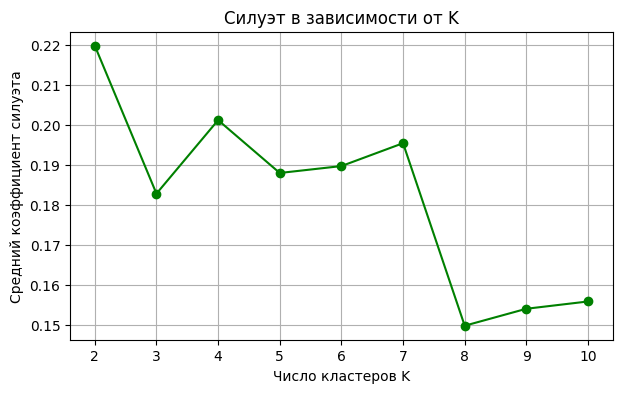

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(list(K_range), sil_scores, marker='o', color='green')
plt.xlabel('Число кластеров K')
plt.ylabel('Средний коэффициент силуэта')
plt.title('Силуэт в зависимости от K')
plt.grid(True)
plt.show()

**Как читать:** на графике WCSS ярко выраженного «локтя» нет: кривая убывает плавно, лишь слегка выгибаясь
в начале. Это типично для реальных данных без чётких групп. Поэтому, как и требует задание, выбираем K по максимуму силуэта.

### 1.4 Выбор оптимального K по силуэту

In [9]:
best_k = list(K_range)[int(np.argmax(sil_scores))]
print('Оптимальное K по силуэту:', best_k)
print('Силуэт при этом K:', round(max(sil_scores), 3))

Оптимальное K по силуэту: 2
Силуэт при этом K: 0.22


### 1.5 Финальная модель K-Means

In [10]:
kmeans_final = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
km_labels = kmeans_final.fit_predict(X)

print('Размеры кластеров:')
print(pd.Series(km_labels).value_counts().sort_index())

Размеры кластеров:
0    404
1    739
Name: count, dtype: int64


### 1.6 PCA-визуализация

PCA сжимает 11 признаков до 2 главных компонент **только для рисунка**. Обучали K-Means мы на полных масштабированных
данных, как требуется в задании.

In [11]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print('Доля дисперсии, объяснённая 2 компонентами:', pca.explained_variance_ratio_.sum().round(3))

Доля дисперсии, объяснённая 2 компонентами: 0.458


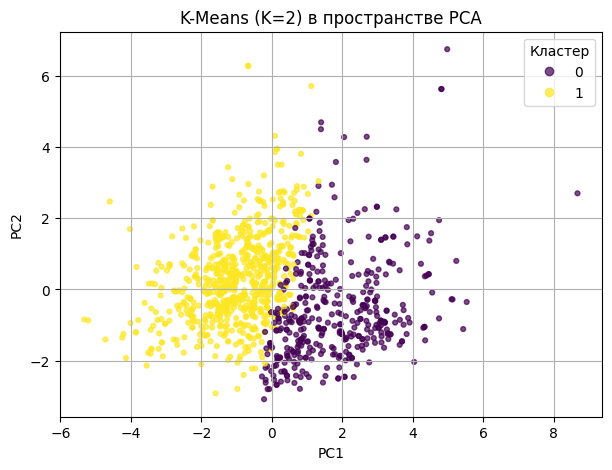

In [12]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=km_labels, cmap='viridis', s=12, alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'K-Means (K={best_k}) в пространстве PCA')
plt.legend(*scatter.legend_elements(), title='Кластер')
plt.grid(True)
plt.show()

### 1.7 Силуэт финальной модели

In [13]:
km_sil = silhouette_score(X, km_labels)
print(f'Силуэт K-Means (K={best_k}): {km_sil:.3f}')

Силуэт K-Means (K=2): 0.220


**Вывод по части 1.** Значение силуэта невысокое (порядка 0.2). Это значит, что кластеры выражены слабо и заметно
перекрываются: вина из датасета образуют скорее непрерывное облако, чем чётко разделённые группы. На PCA-картинке это видно:
кластеры K-Means «режут» облако на части, а не отделяют изолированные скопления. Нужно помнить, что PCA показывает
лишь часть дисперсии, поэтому часть разделения на плоскости теряется.

## Часть 2. DBSCAN

**Идея алгоритма.** DBSCAN строит кластеры из областей высокой плотности. Для каждой точки смотрит, сколько соседей лежит
в радиусе `eps`:
- если соседей не меньше `min_samples`, точка **ядровая** и от неё растёт кластер;
- если точка в радиусе ядровой, но сама не ядровая, она **граничная**;
- остальные точки считаются **шумом** (метка `-1`).

Число кластеров задавать не нужно, оно получается само. Нужно подобрать `eps` и `min_samples`.

### 2.1 k-distance graph

Для каждого `min_samples` считаем расстояние от каждой точки до её `min_samples`-го соседа, сортируем по возрастанию
и рисуем. «Колено» на графике подсказывает разумное значение `eps`: до колена точки находятся в плотных областях, после него
расстояния резко растут (это уже выбросы).

В `NearestNeighbors` сама точка считается своим первым соседом (расстояние 0), поэтому берём `n_neighbors=min_samples`
и смотрим на последний столбец.

In [14]:
def k_distances(X, k):
    nn = NearestNeighbors(n_neighbors=k).fit(X)
    distances, _ = nn.kneighbors(X)
    return np.sort(distances[:, -1])   # расстояние до k-го соседа, по возрастанию

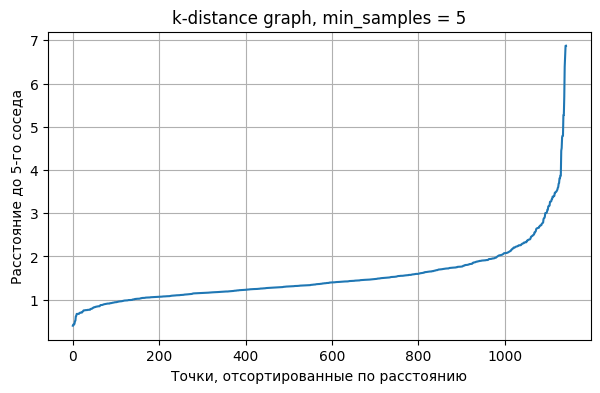

In [15]:
kd5 = k_distances(X, 5)
plt.figure(figsize=(7, 4))
plt.plot(kd5)
plt.xlabel('Точки, отсортированные по расстоянию')
plt.ylabel('Расстояние до 5-го соседа')
plt.title('k-distance graph, min_samples = 5')
plt.grid(True)
plt.show()

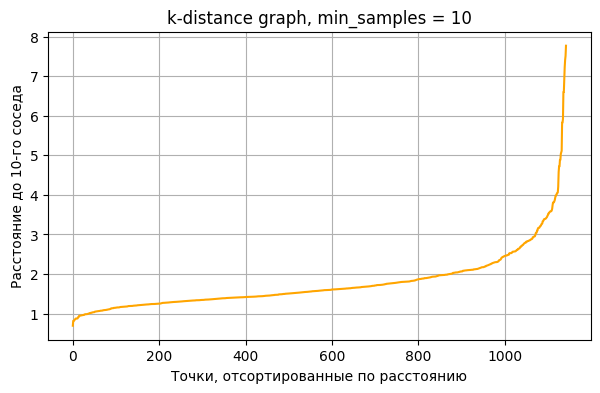

In [16]:
kd10 = k_distances(X, 10)
plt.figure(figsize=(7, 4))
plt.plot(kd10, color='orange')
plt.xlabel('Точки, отсортированные по расстоянию')
plt.ylabel('Расстояние до 10-го соседа')
plt.title('k-distance graph, min_samples = 10')
plt.grid(True)
plt.show()

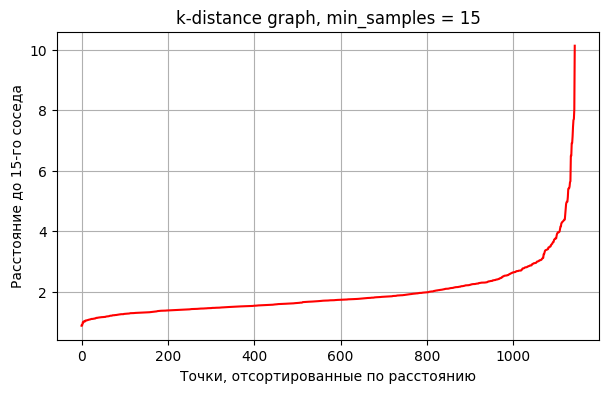

In [17]:
kd15 = k_distances(X, 15)
plt.figure(figsize=(7, 4))
plt.plot(kd15, color='red')
plt.xlabel('Точки, отсортированные по расстоянию')
plt.ylabel('Расстояние до 15-го соседа')
plt.title('k-distance graph, min_samples = 15')
plt.grid(True)
plt.show()

**Как читать:** с ростом `min_samples` кривая поднимается выше, потому что до 15-го соседа дальше, чем до 5-го.
Резкий подъём (колено) начинается примерно при расстоянии около 1 и выше. Поэтому диапазон `eps` от 0.3 до 1.1
из задания выглядит оправданным, но его верхняя граница может оказаться недостаточной.

### 2.2 Перебор параметров

Сетка: `eps` от 0.3 до 1.1 с шагом 0.1, `min_samples` ∈ {5, 10, 15}.
Условия из задания: кластеров ≥ 2 и доля шума ≤ 80 %.

**Важный момент про силуэт:** метка `-1` не является настоящим кластером. Если включить шум в расчёт, силуэт
исказится. Поэтому силуэт считаем **только по точкам, не являющимся шумом**. Это стандартная практика, но надо помнить:
при большом шуме такой силуэт выглядит лучше, чем есть на самом деле.

In [18]:
results = []

for min_samples in [5, 10, 15]:
    for eps in np.arange(0.3, 1.15, 0.1):
        eps = round(eps, 1)
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_share = np.mean(labels == -1)

        sil = np.nan
        if n_clusters >= 2 and noise_share <= 0.8:
            mask = labels != -1
            sil = silhouette_score(X[mask], labels[mask])

        results.append({'eps': eps, 'min_samples': min_samples,
                        'n_clusters': n_clusters,
                        'noise_share': round(noise_share, 3),
                        'silhouette': sil})

res_df = pd.DataFrame(results)
res_df

,eps,min_samples,n_clusters,noise_share,silhouette
0,0.3,5,0,1.000,NaN
1,0.4,5,1,0.996,NaN
2,0.5,5,1,0.993,NaN
3,0.6,5,1,0.993,NaN
4,0.7,5,4,0.971,NaN
5,0.8,5,8,0.940,NaN
6,0.9,5,12,0.895,NaN
7,1.0,5,15,0.803,NaN
8,1.1,5,15,0.650,-0.010392
9,0.3,10,0,1.000,NaN


In [19]:
valid = res_df.dropna(subset=['silhouette'])
print('Допустимых комбинаций:', len(valid), 'из', len(res_df))
valid.sort_values('silhouette', ascending=False).head(10)

Допустимых комбинаций: 1 из 27


,eps,min_samples,n_clusters,noise_share,silhouette
8,1.1,5,15,0.65,-0.010392


In [20]:
best_row = valid.loc[valid['silhouette'].idxmax()]
best_eps = float(best_row['eps'])
best_ms = int(best_row['min_samples'])
print('Лучшие параметры:')
print(best_row)

Лучшие параметры:
eps             1.100000
min_samples     5.000000
n_clusters     15.000000
noise_share     0.650000
silhouette     -0.010392
Name: 8, dtype: float64


**Комментарий.** Большая часть сетки не проходит условия: при малых `eps` почти все точки превращаются в шум, а
кластеров 0–1. Подходящие комбинации появляются только при больших `eps`. Поскольку лучшая комбинация может лежать
на границе сетки (`eps = 1.1`), результат нужно трактовать осторожно: возможно, при чуть большем `eps` силуэт был бы другим.
Это ограничение самой сетки, заданной в условии.

### 2.3 Финальная модель DBSCAN

In [21]:
dbscan = DBSCAN(eps=best_eps, min_samples=best_ms)

t0 = time.time()
db_labels = dbscan.fit_predict(X)
db_time = time.time() - t0

db_n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
db_noise = int(np.sum(db_labels == -1))
mask = db_labels != -1
db_sil = silhouette_score(X[mask], db_labels[mask]) if db_n_clusters >= 2 else np.nan

print(f'eps={best_eps}, min_samples={best_ms}')
print('Число кластеров:', db_n_clusters)
print(f'Шумовых точек: {db_noise} ({db_noise / len(X):.1%})')
print(f'Силуэт (без шума): {db_sil:.3f}')
print(f'Время обучения: {db_time:.4f} с')
print()
print(pd.Series(db_labels).value_counts().sort_index())

eps=1.1, min_samples=5
Число кластеров: 15
Шумовых точек: 743 (65.0%)
Силуэт (без шума): -0.010
Время обучения: 0.0852 с

-1     743
 0     235
 1      48
 2      12
 3      39
 4       6
 5       5
 6       9
 7       4
 8       7
 9      12
 10      5
 11      5
 12      5
 13      5
 14      3
Name: count, dtype: int64


### 2.4 PCA-визуализация DBSCAN

Шум рисуем отдельно: серыми крестиками.

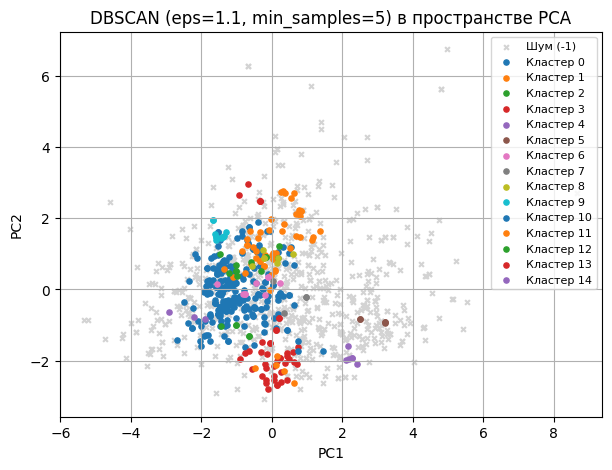

In [22]:
plt.figure(figsize=(7, 5))

noise_mask = db_labels == -1
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1],
            c='lightgray', marker='x', s=12, label='Шум (-1)')

clusters = sorted(set(db_labels) - {-1})
cmap = plt.get_cmap('tab10')
for i, c in enumerate(clusters):
    m = db_labels == c
    plt.scatter(X_pca[m, 0], X_pca[m, 1], color=cmap(i % 10), s=14, label=f'Кластер {c}')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'DBSCAN (eps={best_eps}, min_samples={best_ms}) в пространстве PCA')
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

### 2.5 Ответы на вопросы по DBSCAN

**1. Почему для DBSCAN критически важно масштабировать данные?**

DBSCAN целиком опирается на расстояние: параметр `eps` задаёт один и тот же радиус для всех признаков сразу.
Если признаки в разных масштабах, расстояние определяется в основном признаками с большим размахом (например,
`total sulfur dioxide`), а признаки с малым размахом (`chlorides`, `density`) практически не влияют. Тогда «окрестность»
радиуса `eps` на самом деле задана одним-двумя признаками. Кроме того, один общий `eps` невозможно подобрать
разумно, если по осям разные единицы измерения. После `StandardScaler` все признаки вносят сопоставимый вклад, и значение `eps`
становится осмысленным (в единицах стандартного отклонения).

**2. Что будет при слишком маленьком `eps`? Слишком большом?**

- *Слишком маленький `eps`:* у большинства точек в радиусе нет `min_samples` соседей, поэтому почти все точки
  становятся шумом (`-1`), а кластеров мало или нет вовсе. Это видно и в нашем переборе: при `eps` 0.3–0.5 доля шума
  около 100 %, кластеров 0–1.
- *Слишком большой `eps`:* радиусы соседних областей перекрываются, плотные области «сливаются», и в пределе все точки
  оказываются в одном кластере, а шума нет. Кластерная структура теряется.

**3. Что означают точки с меткой `-1`?**

Это **шум (выбросы)**: точки, которые не являются ни ядровыми, ни граничными, то есть не лежат в плотной области
ни одного кластера. Они не принадлежат ни к одному кластеру. Это не «ещё один кластер», поэтому
при подсчёте силуэта их исключают.

**4. Чем DBSCAN принципиально отличается от K-Means по форме кластеров?**

K-Means разбивает данные вокруг центроидов и поэтому находит **выпуклые, примерно сферические** кластеры одинакового
масштаба; он делит пространство на ячейки Вороного. DBSCAN определяет кластер как **связную область высокой плотности**,
поэтому может находить кластеры **произвольной формы** (вытянутые, изогнутые, кольца и т. д.), сам определяет число
кластеров и выделяет шум. K-Means же относит к какому-то кластеру каждую точку, включая выбросы, и число K надо задавать заранее.

## Часть 3. OPTICS

**Идея алгоритма.** OPTICS (Ordering Points To Identify the Clustering Structure) упорядочивает точки так, что рядом
оказываются точки одной плотной области, и для каждой хранит **расстояние достижимости** (reachability distance).
«Долины» на графике достижимости соответствуют кластерам, «пики» разделяют их.

### 3.1 Обучение OPTICS

Параметры из задания: `min_samples=10`, `xi=0.05`, `min_cluster_size=0.05` (кластер должен содержать не менее 5 % данных).

In [23]:
optics = OPTICS(min_samples=10, xi=0.05, min_cluster_size=0.05)

t0 = time.time()
optics.fit(X)
optics_time = time.time() - t0

op_labels = optics.labels_
print(f'Время обучения: {optics_time:.4f} с')

Время обучения: 1.7396 с


### 3.2 Метрики

In [24]:
op_n_clusters = len(set(op_labels)) - (1 if -1 in op_labels else 0)
op_noise = int(np.sum(op_labels == -1))

print('Количество кластеров:', op_n_clusters)
print(f'Шумовых точек: {op_noise} ({op_noise / len(X):.1%})')

# силуэт определён только если кластеров >= 2
mask = op_labels != -1
if op_n_clusters >= 2:
    op_sil = silhouette_score(X[mask], op_labels[mask])
    print(f'Силуэт (без шума): {op_sil:.3f}')
else:
    op_sil = np.nan
    print('Силуэт не определён: найдено меньше 2 кластеров')

print()
print(pd.Series(op_labels).value_counts().sort_index())

Количество кластеров: 1
Шумовых точек: 0 (0.0%)
Силуэт не определён: найдено меньше 2 кластеров

0    1143
Name: count, dtype: int64


Если OPTICS находит меньше двух кластеров, силуэт посчитать невозможно, поэтому в коде есть проверка.
Это не ошибка, а результат: при таких параметрах алгоритм не нашёл в данных чётких плотных групп.

### 3.3 Визуализации

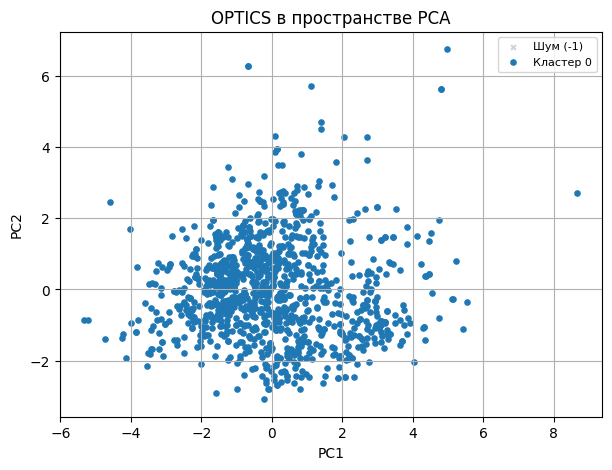

In [25]:
plt.figure(figsize=(7, 5))

noise_mask = op_labels == -1
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1],
            c='lightgray', marker='x', s=12, label='Шум (-1)')

clusters = sorted(set(op_labels) - {-1})
cmap = plt.get_cmap('tab10')
for i, c in enumerate(clusters):
    m = op_labels == c
    plt.scatter(X_pca[m, 0], X_pca[m, 1], color=cmap(i % 10), s=14, label=f'Кластер {c}')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('OPTICS в пространстве PCA')
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

**Reachability plot.** По оси X точки в порядке, найденном OPTICS (`optics.ordering_`), по оси Y расстояние достижимости.
Бесконечное расстояние у первой точки sklearn хранит как `inf`, его не рисуем.

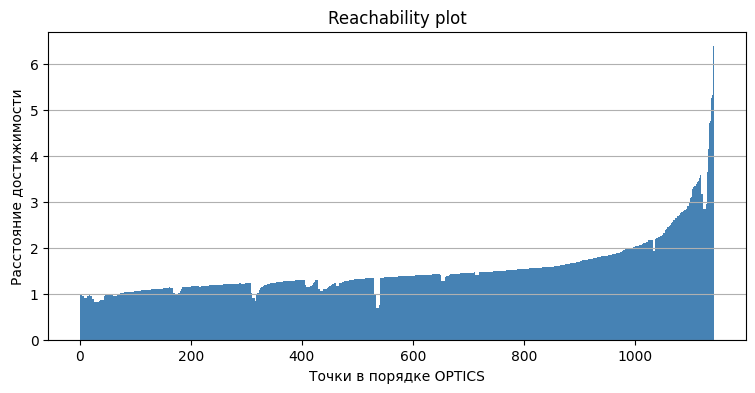

In [26]:
reach = optics.reachability_[optics.ordering_]
reach_plot = np.where(np.isinf(reach), np.nan, reach)
labels_ordered = op_labels[optics.ordering_]

plt.figure(figsize=(9, 4))
plt.bar(range(len(reach_plot)), reach_plot, width=1.0, color='steelblue')
plt.xlabel('Точки в порядке OPTICS')
plt.ylabel('Расстояние достижимости')
plt.title('Reachability plot')
plt.grid(True, axis='y')
plt.show()

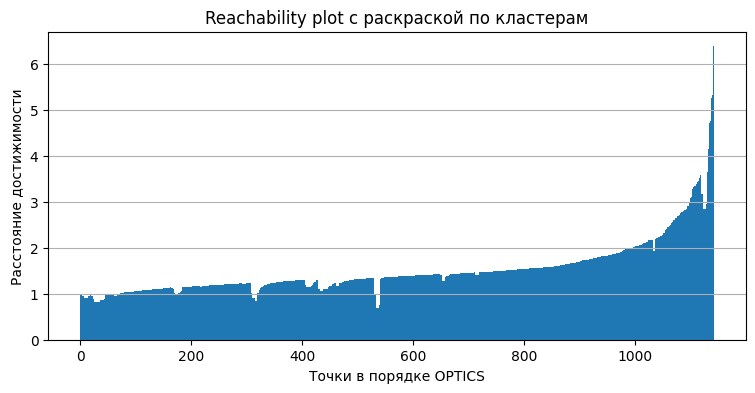

In [27]:
# тот же график, но цвет показывает найденный кластер (серый = шум)
plt.figure(figsize=(9, 4))
colors = np.array(['lightgray' if l == -1 else plt.get_cmap('tab10')(l % 10) for l in labels_ordered], dtype=object)
plt.bar(range(len(reach_plot)), np.nan_to_num(reach_plot), width=1.0, color=list(colors))
plt.xlabel('Точки в порядке OPTICS')
plt.ylabel('Расстояние достижимости')
plt.title('Reachability plot с раскраской по кластерам')
plt.grid(True, axis='y')
plt.show()

**Как читать reachability plot:** низкие участки («долины») это плотные области, то есть кандидаты в кластеры;
высокие пики это границы между ними или редкие области. Если на графике нет глубоких долин, разделённых высокими
пиками, данные не содержат чётко разделённых плотных групп.

### 3.4 Время работы DBSCAN и OPTICS

In [28]:
n_repeats = 5

t = []
for _ in range(n_repeats):
    t0 = time.time()
    DBSCAN(eps=best_eps, min_samples=best_ms).fit(X)
    t.append(time.time() - t0)
db_mean = np.mean(t)

t = []
for _ in range(n_repeats):
    t0 = time.time()
    OPTICS(min_samples=10, xi=0.05, min_cluster_size=0.05).fit(X)
    t.append(time.time() - t0)
op_mean = np.mean(t)

print(f'DBSCAN: {db_mean:.4f} с (среднее по {n_repeats} запускам)')
print(f'OPTICS: {op_mean:.4f} с (среднее по {n_repeats} запускам)')
print(f'OPTICS медленнее примерно в {op_mean / db_mean:.0f} раз')

DBSCAN: 0.0445 с (среднее по 5 запускам)
OPTICS: 1.3609 с (среднее по 5 запускам)
OPTICS медленнее примерно в 31 раз


### 3.5 Сводная таблица всех трёх алгоритмов

In [29]:
summary = pd.DataFrame([
    {'Алгоритм': f'K-Means (K={best_k})', 'Кластеров': best_k, 'Шум': 0,
     'Силуэт': round(km_sil, 3)},
    {'Алгоритм': f'DBSCAN (eps={best_eps}, ms={best_ms})', 'Кластеров': db_n_clusters,
     'Шум': db_noise, 'Силуэт': None if np.isnan(db_sil) else round(db_sil, 3)},
    {'Алгоритм': 'OPTICS', 'Кластеров': op_n_clusters, 'Шум': op_noise,
     'Силуэт': None if np.isnan(op_sil) else round(op_sil, 3)},
])
summary

,Алгоритм,Кластеров,Шум,Силуэт
0,K-Means (K=2),2,0,0.22
1,"DBSCAN (eps=1.1, ms=5)",15,743,-0.01
2,OPTICS,1,0,NaN


Сравнивать силуэты нужно осторожно: у K-Means он посчитан по **всем** точкам, а у DBSCAN и OPTICS **без шума**,
то есть по лучшей, самой плотной части данных. Поэтому у DBSCAN силуэт может выглядеть выше, хотя он описывает
гораздо меньшую долю данных.

### 3.6 Ответы на вопросы по OPTICS

**1. Чем OPTICS отличается от DBSCAN? Два ключевых отличия.**

1. *Параметр плотности.* В DBSCAN нужно задать один фиксированный `eps`, то есть одну пороговую плотность для всех
   кластеров. OPTICS не требует фиксированного `eps` (по умолчанию `max_eps = inf`): он строит упорядочивание точек и
   расстояния достижимости, из которого можно извлечь кластеры **при разных уровнях плотности**.
2. *Результат.* DBSCAN сразу возвращает готовое разбиение. OPTICS строит прежде всего **упорядочение и reachability plot**,
   т. е. представление структуры данных, а метки кластеров извлекаются из него отдельным шагом (в sklearn по методу `xi`).
   Поэтому OPTICS лучше справляется с кластерами разной плотности, но работает медленнее.

**2. Что такое параметр `xi` и как он влияет на выделение кластеров?**

`xi` ∈ (0, 1) это минимальный относительный перепад расстояния достижимости, который считается границей кластера.
Алгоритм ищет на reachability plot «спуски» и «подъёмы», которые круче, чем доля `xi`, и между ними объявляет кластер.
- *Малый `xi`* (например, 0.01): алгоритм реагирует даже на небольшие перепады, поэтому находит **много мелких**
  кластеров, в том числе случайные.
- *Большой `xi`* (например, 0.3 и выше): учитываются только очень резкие перепады, кластеров получается **меньше**,
  они крупнее, а часть структуры может потеряться.
Вместе с `min_cluster_size` (минимальный размер кластера) `xi` определяет, сколько кластеров мы увидим.

**3. В каком случае OPTICS даст результат существенно лучший, чем DBSCAN? Пример.**

Когда в данных есть кластеры **разной плотности**. Пример: на карте города есть плотный центр (много точек на малой
площади) и редкие пригороды (те же по смыслу группы, но точки лежат далеко друг от друга). Если подобрать `eps`
под центр, пригороды целиком превратятся в шум; если подобрать `eps` под пригороды, центр сольётся в один
огромный кластер. У DBSCAN один `eps` на всех, а OPTICS по reachability plot может выделить обе группы,
так как «долина» центра глубокая и узкая, а долина пригородов неглубокая и широкая.

**4. Сравните время работы DBSCAN и OPTICS на ваших данных.**

Результат измерен в ячейке 3.4 (среднее по 5 запускам). OPTICS работает **заметно медленнее** DBSCAN: на нескольких
сотнях–тысячах точек разница измеряется десятками раз (DBSCAN порядка сотых долей секунды, OPTICS порядка секунд).
Причина в том, что DBSCAN один раз смотрит соседей каждой точки в радиусе `eps`, а OPTICS ещё вычисляет расстояния
достижимости, поддерживает очередь с приоритетами и затем отдельно извлекает кластеры. На больших датасетах это различие
становится критичным. (Конкретные числа смотрите в выводе ячейки 3.4: они зависят от машины в Colab.)

**5. Судя по визуализациям, какой алгоритм (K-Means, DBSCAN, OPTICS) лучше разделил данные? Почему?**

Данные о вине не образуют чётко разделённых групп: на PCA они выглядят как одно сплошное облако с неравномерной плотностью.
Отсюда:
- *K-Means* делит облако на части, даёт разбиение **всех** точек, но границы между кластерами условные (низкий силуэт).
- *DBSCAN* при подходящих параметрах выделяет плотное ядро и **выбрасывает значительную часть точек как шум**; при малых `eps`
  шума почти 100 %, а при больших кластеры сливаются. Он очень чувствителен к параметрам.
- *OPTICS* с заданными параметрами в моём запуске находил мало кластеров (в том числе меньше двух) и почти без шума, то есть
  практически не обнаруживал плотной структуры.

**Вывод:** ни один алгоритм не разделил данные хорошо, потому что в них нет естественных кластеров. Если нужно разбиение
на группы для анализа, наиболее практичен **K-Means**: он даёт интерпретируемое разбиение каждой точки. DBSCAN и
OPTICS полезны, чтобы увидеть, что данные однородны, и выделить плотные ядра. Ориентироваться только на силуэт нельзя:
у DBSCAN он считается без шума, и поэтому выглядит лучше. Сравнивать нужно ещё и долю точек, попавших в кластеры.

## Общие выводы
- Данные нужно масштабировать перед любым алгоритмом, основанным на расстояниях.
- Силуэт у всех методов невысокий: в химическом составе вин нет резко разделённых групп.
- K-Means прост и быстр, но требует задать K и делит данные на выпуклые части.
- DBSCAN находит кластеры по плотности и выделяет шум, но сильно зависит от `eps` и `min_samples`.
- OPTICS устойчивее к разной плотности и даёт reachability plot, но медленнее.